# Visualizing BigQuery data in Agent Platform Workbench

Agent Platform Workbench (formerly Vertex AI Workbench) is JupyterLab running on a VM in your project. You choose the machine and pay for it while it runs, so stop the instance when you're done.

This notebook is adapted from a Google tutorial. It uses the BigQuery Python client and pandas to chart the `natality` sample table (US births, 1969 to 2008).

**To run it:** search for **Workbench** in the console and create an instance in zone `us-east1-b` (the default machine is fine). When it's ready, click **Open JupyterLab** and upload this file. Workbench runs as your project, so there's no login step.

## Using Jupyter magics to query BigQuery data

A cell that starts with `%%bigquery` runs its contents as SQL and shows the result as a pandas `DataFrame`.

In [1]:
%%bigquery
SELECT * FROM `bigquery-public-data.samples.natality` LIMIT 5

,source_year,year,month,day,wday,state,is_male,child_race,weight_pounds,plurality,...,alcohol_use,drinks_per_week,weight_gain_pounds,born_alive_alive,born_alive_dead,born_dead,ever_born,father_race,father_age,record_weight
0,2005,2005,6,<NA>,7,NaN,True,<NA>,8.855969,1,...,<NA>,<NA>,22,7,0,4,8,<NA>,46,1
1,2005,2005,7,<NA>,2,NaN,False,<NA>,9.413739,1,...,False,<NA>,10,7,0,1,8,1,41,1
2,2005,2005,6,<NA>,4,NaN,False,<NA>,8.818490,1,...,<NA>,<NA>,59,1,<NA>,1,<NA>,<NA>,99,1
3,2005,2005,11,<NA>,3,NaN,True,<NA>,8.624484,1,...,<NA>,<NA>,31,2,<NA>,<NA>,<NA>,<NA>,99,1
4,2005,2005,6,<NA>,1,NaN,False,<NA>,7.436192,1,...,False,<NA>,10,0,0,2,1,78,33,1


The following cell executes a query of the BigQuery natality public dataset and returns the total births by year.

In [2]:
%%bigquery
SELECT
    source_year AS year,
    COUNT(is_male) AS birth_count
FROM `bigquery-public-data.samples.natality`
GROUP BY year
ORDER BY year ASC

,year,birth_count
0,1969,1800103
1,1970,1868900
2,1971,1781774
3,1972,1749402
4,1973,1839736
5,1974,2029150
6,1975,2232406
7,1976,2463852
8,1977,2772206
9,1978,2865686


The next cell runs the same query but saves the result in a variable, `total_births`, named after `%%bigquery`. You can then use it in Python.

In [3]:
%%bigquery total_births
SELECT
    source_year AS year,
    COUNT(is_male) AS birth_count
FROM `bigquery-public-data.samples.natality`
GROUP BY year
ORDER BY year ASC

`DataFrame.plot` draws a bar chart of the result. The [pandas visualization guide](https://pandas.pydata.org/docs/user_guide/visualization.html) has more chart types.

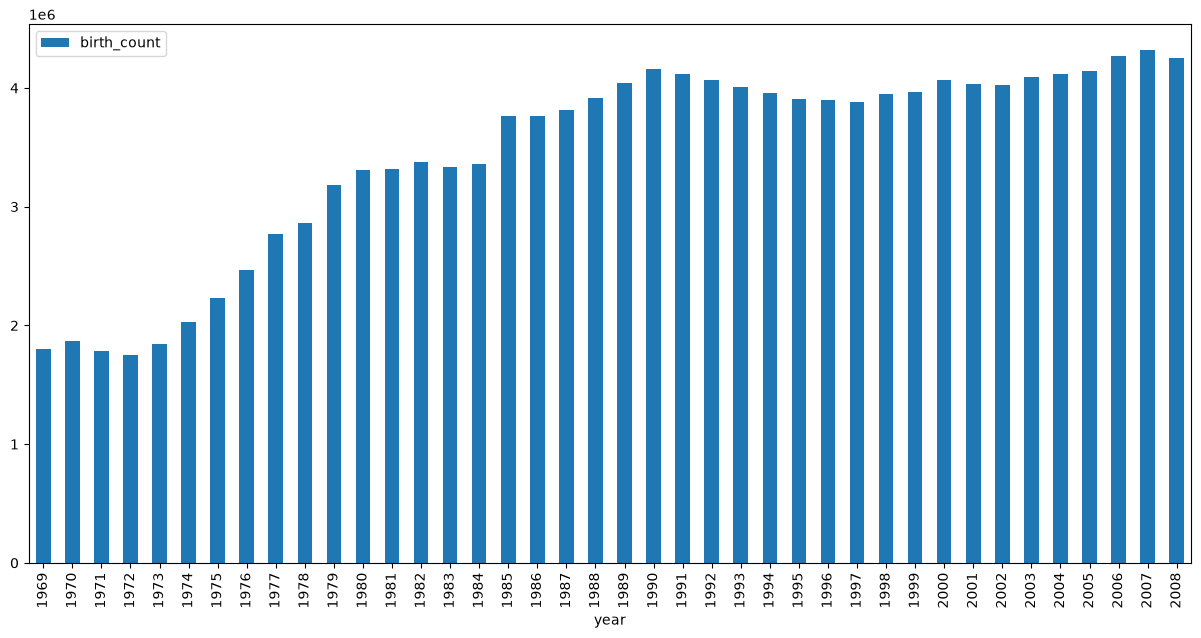

In [4]:
total_births.plot(kind='bar', x='year', y='birth_count', figsize=(15, 7));

Next, births by weekday. The `wday` column has nulls, so the query drops them.

In [5]:
%%bigquery births_by_weekday
SELECT
    wday,
    SUM(CASE WHEN is_male THEN 1 ELSE 0 END) AS male_births,
    SUM(CASE WHEN is_male THEN 0 ELSE 1 END) AS female_births
FROM `bigquery-public-data.samples.natality`
WHERE wday IS NOT NULL
GROUP BY wday
ORDER BY wday ASC

Visualize the query results using a line chart.

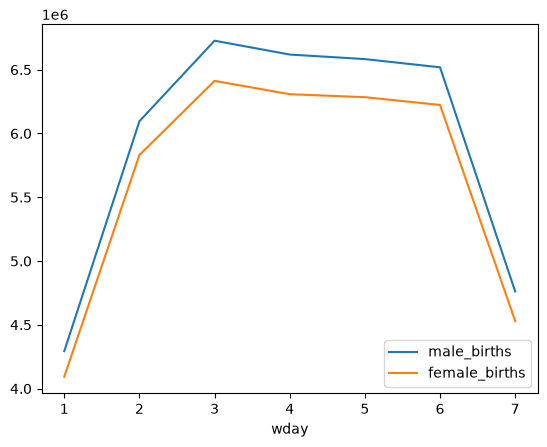

In [6]:
births_by_weekday.plot(x='wday');

## Using Python to query BigQuery data

Behind the scenes, `%%bigquery` uses the BigQuery Python client library. Calling the client yourself gives you more control, and lets you mix SQL with Python code in the same cell.

Start by creating a client. It sends your queries to the BigQuery API.

In [7]:
from google.cloud import bigquery

client = bigquery.Client()

[`Client.query`](https://cloud.google.com/python/docs/reference/bigquery/latest/google.cloud.bigquery.client.Client#google_cloud_bigquery_client_Client_query) runs a query, and `to_dataframe()` turns the result into a DataFrame. This one counts plural births (2 for twins, 3 for triplets, and so on) by year.

In [8]:
sql = """
SELECT
    plurality,
    COUNT(1) AS count,
    year
FROM
    `bigquery-public-data.samples.natality`
WHERE
    NOT IS_NAN(plurality) AND plurality > 1
GROUP BY
    plurality, year
ORDER BY
    count DESC
"""
df = client.query(sql).to_dataframe()
df.head()

,plurality,count,year
0,2,139209,2007
1,2,138866,2008
2,2,137239,2006
3,2,133285,2005
4,2,132344,2004


Pivot the data so each plurality is a column, then draw a stacked bar chart of plural births over time.

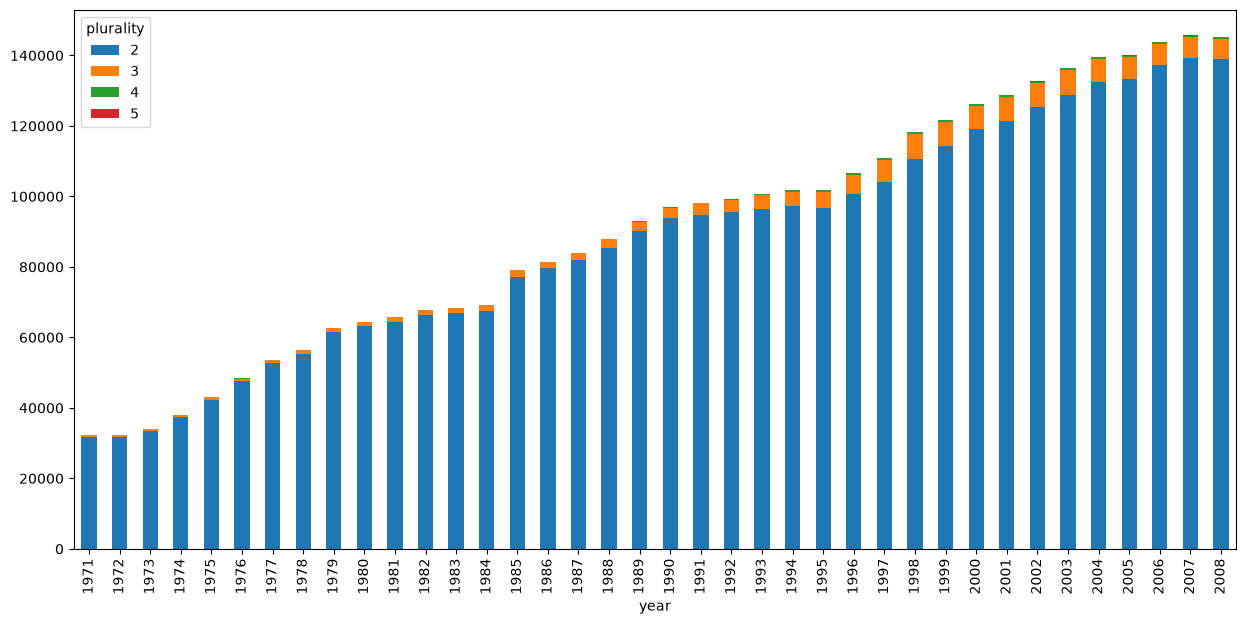

In [9]:
pivot_table = df.pivot(index='year', columns='plurality', values='count')
pivot_table.plot(kind='bar', stacked=True, figsize=(15, 7));

Count births by the number of weeks of gestation (99 means unknown, so it's excluded).

In [10]:
sql = """
SELECT
    gestation_weeks,
    COUNT(1) AS count
FROM
    `bigquery-public-data.samples.natality`
WHERE
    NOT IS_NAN(gestation_weeks) AND gestation_weeks <> 99
GROUP BY
    gestation_weeks
ORDER BY
    gestation_weeks
"""
df = client.query(sql).to_dataframe()

Chart the result.

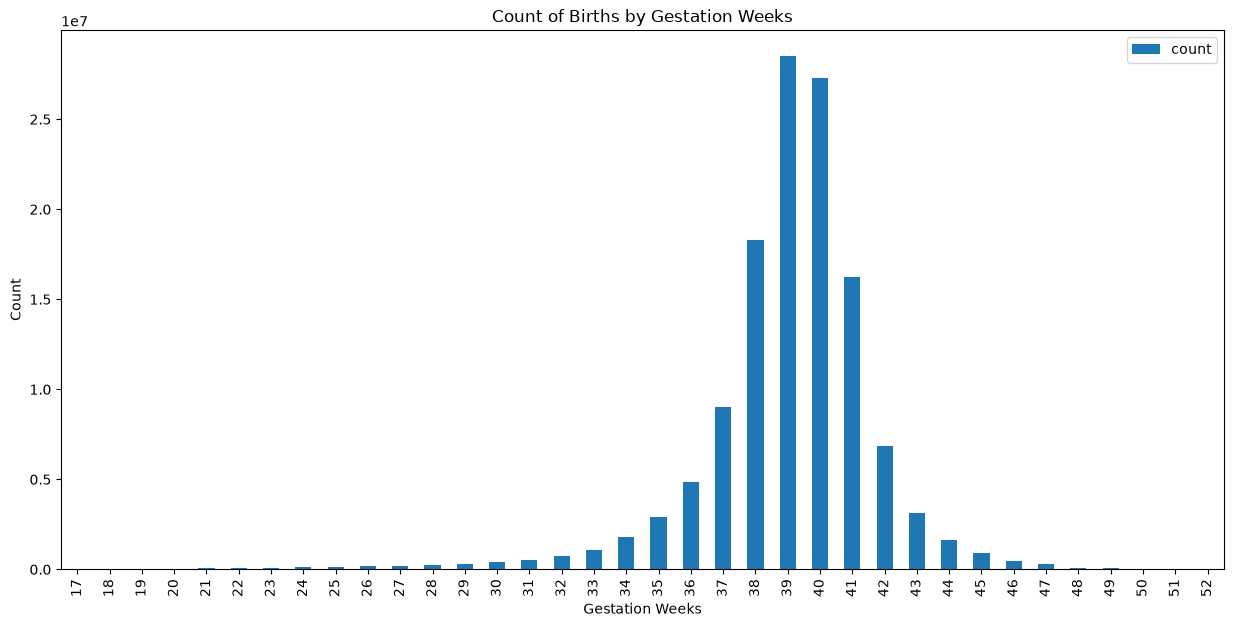

In [11]:
ax = df.plot(kind='bar', x='gestation_weeks', y='count', figsize=(15,7))
ax.set_title('Count of Births by Gestation Weeks')
ax.set_xlabel('Gestation Weeks')
ax.set_ylabel('Count');

## Before you leave

Stop the instance from the Workbench page. A stopped instance only bills for its disk; delete it when the course no longer needs it.

More reading: [running queries](https://cloud.google.com/bigquery/docs/running-queries) and the [GoogleSQL reference](https://cloud.google.com/bigquery/docs/reference/standard-sql/query-syntax).